Extração de características do grafo da imagem

---

Bibliotecas

In [1]:
import cv2

import matplotlib.pyplot as plt
import networkx          as nx
import numpy             as np


---

Carregando a imagem

In [2]:
josefran_image = cv2.imread("../assets/josefran.jpg")
josefran_image = cv2.cvtColor(josefran_image, cv2.COLOR_BGR2GRAY)

josefran_image.shape

(640, 640)

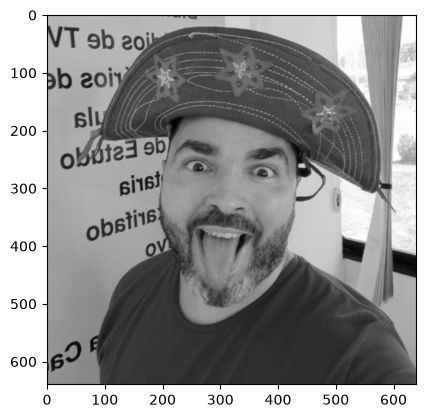

In [3]:
plt.imshow(josefran_image, cmap='gray')
plt.show()

Redimensionando para $64\times64$

In [4]:
josefran_image = cv2.resize(josefran_image, (64, 64), cv2.INTER_LINEAR)
josefran_image.shape

(64, 64)

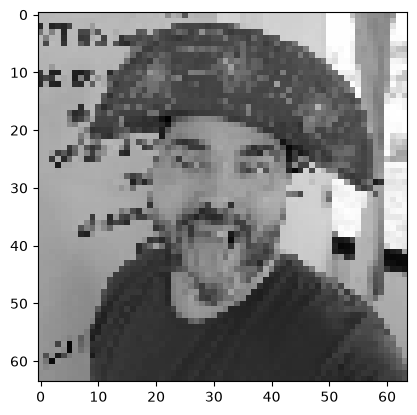

In [5]:
plt.imshow(josefran_image, cmap='gray')
plt.show()

---

Gerando um grafo da imagem exemplo

In [6]:
def construir_grafo_imagem(matriz_pixels, vizinhanca=4, limiar=10):
    altura, largura = matriz_pixels.shape
    grafo           = { (i, j): [] for i in range(altura) for j in range(largura) }
    
    # Definir deslocamentos com base na vizinhança
    if vizinhanca == 4:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    elif vizinhanca == 8:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1), 
                    (-1, -1), (-1, 1), (1, -1), (1, 1)]
    else:
        raise ValueError("A vizinhança deve ser 4 ou 8.")

    for i in range(altura):
        for j in range(largura):
            u = (i, j)
            intensidade_u = matriz_pixels[i, j]
            
            for di, dj in direcoes:
                ni, nj = i + di, j + dj
                
                if 0 <= ni < altura and 0 <= nj < largura:
                    v = (ni, nj)
                    intensidade_v = matriz_pixels[ni, nj]
                    
                    if abs(int(intensidade_u) - int(intensidade_v)) <= limiar:
                        grafo[u].append(v)
                        
    return grafo

In [7]:
josefran_graph = construir_grafo_imagem(josefran_image)

---

In [8]:
def obter_componentes_conexas(grafo):
    """
    Identifica as componentes conexas de um grafo não direcionado usando DFS iterativa.
    Retorna uma lista de listas de vértices, ordenada do maior para o menor componente.
    """
    visitado = set()
    componentes = []

    for inicio in grafo:
        if inicio in visitado:
            continue

        comp = []
        pilha = [inicio]
        visitado.add(inicio)

        while pilha:
            u = pilha.pop()
            comp.append(u)

            for v in grafo.get(u, []):
                if v not in visitado:
                    visitado.add(v)
                    pilha.append(v)

        componentes.append(comp)

    componentes.sort(key=len, reverse=True)
    return componentes


def encontrar_pontes_e_articulacoes(grafo):
    """
    Identifica pontes e vértices de articulação usando DFS iterativa e low[].
    """
    tin = {}
    low = {}
    visitado = set()
    pontes = set()
    articulacoes = set()
    timer = 0

    for raiz in grafo:
        if raiz in visitado:
            continue

        visitado.add(raiz)
        timer += 1
        tin[raiz] = low[raiz] = timer
        filhos_raiz = 0

        pilha = [[raiz, None, iter(grafo.get(raiz, []))]]

        while pilha:
            u, pai, vizinhos = pilha[-1]

            try:
                v = next(vizinhos)
                if v == pai:
                    continue

                if v in visitado:
                    if tin[v] < low[u]:
                        low[u] = tin[v]
                else:
                    if pai is None:
                        filhos_raiz += 1

                    visitado.add(v)
                    timer += 1
                    tin[v] = low[v] = timer
                    pilha.append([v, u, iter(grafo.get(v, []))])

            except StopIteration:
                pilha.pop()
                if pilha:
                    p = pilha[-1][0]
                    avo = pilha[-1][1]

                    if low[u] < low[p]:
                        low[p] = low[u]

                    if low[u] > tin[p]:
                        pontes.add((p, u) if p < u else (u, p))

                    if avo is not None and low[u] >= tin[p]:
                        articulacoes.add(p)

        if filhos_raiz >= 2:
            articulacoes.add(raiz)

    return pontes, articulacoes


def extrair_caracteristicas_grafo(grafo):
    """
    Extrai as principais características estruturais de um grafo representado
    como dicionário de adjacência {u: [v1, v2, ...]}.
    """
    num_vertices = len(grafo)

    # Como o grafo é não direcionado, cada aresta {u, v} aparece duas vezes (u->v e v->u)
    arestas_unicas = set()
    soma_graus = 0

    for u, vizinhos in grafo.items():
        soma_graus += len(vizinhos)
        for v in vizinhos:
            aresta = (u, v) if u < v else (v, u)
            arestas_unicas.add(aresta)

    num_arestas = len(arestas_unicas)
    grau_medio = (soma_graus / num_vertices) if num_vertices > 0 else 0.0

    componentes = obter_componentes_conexas(grafo)
    num_componentes = len(componentes)
    tamanho_maior_componente = len(componentes[0]) if componentes else 0

    pontes, articulacoes = encontrar_pontes_e_articulacoes(grafo)

    return {
        "numero_vertices": num_vertices,
        "numero_arestas": num_arestas,
        "numero_componentes": num_componentes,
        "grau_medio": grau_medio,
        "tamanho_maior_componente": tamanho_maior_componente,
        "numero_pontes": len(pontes),
        "numero_articulacoes": len(articulacoes),
        "componentes": componentes,
        "pontes": pontes,
        "articulacoes": articulacoes,
    }

In [9]:
caracteristicas = extrair_caracteristicas_grafo(josefran_graph)

print(f"Número de vértices:         {caracteristicas['numero_vertices']}")
print(f"Número de arestas:          {caracteristicas['numero_arestas']}")
print(f"Número de componentes:      {caracteristicas['numero_componentes']}")
print(f"Grau médio:                 {caracteristicas['grau_medio']:.4f}")
print(f"Tamanho da maior componente:{caracteristicas['tamanho_maior_componente']}")
print(f"Número de pontes:           {caracteristicas['numero_pontes']}")
print(f"Número de articulações:     {caracteristicas['numero_articulacoes']}")

Número de vértices:         4096
Número de arestas:          5270
Número de componentes:      626
Grau médio:                 2.5732
Tamanho da maior componente:828
Número de pontes:           749
Número de articulações:     564
